# Naive Bayes từ đầu bằng PyTorch — Phân loại cảm xúc bình luận phim "Mưa đỏ"

**Mục tiêu:** cài đặt *from scratch* (chỉ dùng tensor operations của PyTorch, chạy được trên GPU):
1. TF-IDF vectorizer (unigram + bigram, `min_df`, `sublinear_tf`, L2-norm),
2. Multinomial Naive Bayes (Laplace/Lidstone smoothing, log-space),
3. các metric (confusion matrix, precision/recall/F1, macro-F1, bootstrap CI).

**Quy trình đánh giá (chống leakage):**
- Chia train/val/test = 70/15/15, stratified theo nhãn, **group theo `Clean Text`** (các bình luận trùng text luôn nằm cùng một tập).
- TF-IDF (vocab, IDF) **chỉ fit trên train**.
- Hyperparameter chọn bằng macro-F1 trên **val**; **test chỉ chấm một lần** ở cuối.

**Thư viện ngoài PyTorch chỉ dùng cho:** đọc Excel (`pandas`), thuật toán chia group-stratified (`StratifiedGroupKFold`), vẽ hình (`matplotlib`), và **đối chiếu tính đúng đắn** với `scikit-learn` (các ô có tiêu đề *Kiểm tra*). Bản thân vectorizer, mô hình, metric đều tự cài đặt.

In [1]:
import json, re, math, itertools, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64          # float64 để đối chiếu số học chính xác với sklearn

ROOT = Path.cwd()
while not (ROOT / "Data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "Data" / "final_labeled_clean_v3.xlsx"
SPLIT_DIR = ROOT / "models" / "Naive_Bayes" / "datasets" / "splits"
OUT = ROOT / "models" / "Naive_Bayes"
LABELS = ["Negative", "Neutral", "Positive"]
L2I = {l: i for i, l in enumerate(LABELS)}

print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu")
print("ROOT:", ROOT)

torch 2.8.0+cu128 | device: cuda | NVIDIA A100-PCIE-40GB
ROOT: /users/PAS3290/binhminh123/MinhHieu-PromptPrunning/BTL-PTKPDLVB-Phan_Loai_Cam_Xuc_Mua_Do


## 1. Dữ liệu và chia train / val / test

Dùng cột `Clean Text` (đầu vào) và `Final Label` (nhãn). Có 68 dòng `Clean Text` trùng nhau (trong đó 2 nhóm bị gán nhãn mâu thuẫn), nên chia **theo nhóm text** để một câu không xuất hiện ở cả train lẫn test.

`StratifiedGroupKFold(20 folds)` → mỗi fold ≈ 5%: 3 fold = test (15%), 3 fold = val (15%), 14 fold = train (70%).

In [2]:
from sklearn.model_selection import StratifiedGroupKFold

df = pd.read_excel(DATA)
df["Clean Text"] = df["Clean Text"].fillna("").astype(str)
y_all = df["Final Label"].map(L2I).values

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, df["Final Label"].values, df["Clean Text"].values)]
test_idx  = np.sort(np.concatenate(folds[:3]))
val_idx   = np.sort(np.concatenate(folds[3:6]))
train_idx = np.sort(np.concatenate(folds[6:]))

# --- Kiểm tra không rò rỉ ---
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))
txt = lambda idx: set(df.loc[idx, "Clean Text"])
assert not (txt(train_idx) & txt(val_idx)) and not (txt(train_idx) & txt(test_idx)) and not (txt(val_idx) & txt(test_idx))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)

SPLIT_DIR.mkdir(exist_ok=True)
for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    df.iloc[idx][["Comment ID", "Clean Text", "Final Label"]].to_csv(SPLIT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

split_info = {n: {"size": int(len(i)), **df.iloc[i]["Final Label"].value_counts().to_dict()}
              for n, i in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
display(pd.DataFrame(split_info).T[["size"] + LABELS])

X_tr_txt, X_va_txt, X_te_txt = (df.loc[i, "Clean Text"].tolist() for i in (train_idx, val_idx, test_idx))
y_tr, y_va, y_te = (torch.tensor(y_all[i], device=DEVICE) for i in (train_idx, val_idx, test_idx))

,size,Negative,Neutral,Positive
train,1491,259,320,912
val,309,58,72,179
test,287,52,46,189


## 2. Cơ sở toán học

**Ký hiệu.** $N$ = số văn bản; $V$ = kích thước từ vựng; $C=3$ lớp; $\mathbf{x}\in\mathbb{R}^{V}$ = vector TF-IDF của một văn bản; $y\in\{1..C\}$.

### 2.1 TF-IDF (cấu hình giống `sklearn`)
$$
\text{tf}'(t,d)=1+\ln \text{tf}(t,d)\ (\text{sublinear}),\qquad
\text{idf}(t)=\ln\frac{1+N}{1+\text{df}(t)}+1,\qquad
\mathbf{x}_d=\frac{\text{tf}'(t,d)\cdot\text{idf}(t)}{\lVert\cdot\rVert_2}.
$$
$\text{df}(t)$ = số văn bản **train** chứa $t$. Từ có $\text{df}<$ `min_df` bị bỏ. Term gồm unigram và bigram.

### 2.2 Multinomial Naive Bayes
Giả định các đặc trưng độc lập có điều kiện theo lớp ("naive"):
$$
P(y=c\mid\mathbf{x})\propto P(c)\prod_{t}P(t\mid c)^{x_t}
\;\Longrightarrow\;
\hat y=\arg\max_c\Big[\ln\pi_c+\sum_t x_t\,\ln\theta_{ct}\Big].
$$
Ước lượng với **Lidstone smoothing** (tham số $\alpha$; $\alpha=1$ là Laplace):
$$
\theta_{ct}=\frac{\alpha+\sum_{d:y_d=c}x_{dt}}{\alpha V+\sum_{t'}\sum_{d:y_d=c}x_{dt'}},\qquad
\pi_c=\frac{N_c}{N}\ (\text{hoặc }1/C\text{ nếu }\texttt{fit\_prior=False}).
$$
Làm việc trong **log-space** để tránh underflow. Với TF-IDF (số thực không âm) thay cho đếm nguyên: công thức vẫn dùng được vì chỉ cần $x_{dt}\ge 0$ (cách dùng phổ biến nhưng không còn là mô hình multinomial "thuần" về mặt xác suất).

**Độ phức tạp.** Huấn luyện: một phép nhân ma trận $\mathbf{Y}^\top\mathbf{X}$, $O(NVC)$ (dạng dense; $O(\text{nnz}\cdot C)$ nếu sparse). Dự đoán: $\mathbf{X}\,\log\Theta^\top$, $O(N V C)$ cho $N$ văn bản. Bộ nhớ tham số: $O(VC)$.

## 3. TF-IDF vectorizer tự cài đặt

In [3]:
TOKEN_RE = re.compile(r"(?u)\b\w\w+\b")   # cùng quy ước với sklearn: bỏ token 1 ký tự; '_' nằm trong \w nên từ ghép 'anh_trai' giữ nguyên

class TfidfTorch:
    def __init__(self, ngram_range=(1, 2), min_df=2, sublinear_tf=True, device=DEVICE, dtype=DTYPE):
        self.ngram_range, self.min_df, self.sublinear_tf = ngram_range, min_df, sublinear_tf
        self.device, self.dtype = device, dtype

    def _analyze(self, text):
        toks = TOKEN_RE.findall(text.lower())
        lo, hi = self.ngram_range
        grams = list(toks) if lo == 1 else []
        for n in range(max(lo, 2), hi + 1):
            grams += [" ".join(toks[i:i + n]) for i in range(len(toks) - n + 1)]
        return grams

    def fit(self, texts):
        df_cnt = Counter()
        for t in texts:
            df_cnt.update(set(self._analyze(t)))
        self.vocab_ = sorted(w for w, c in df_cnt.items() if c >= self.min_df)
        self.index_ = {w: i for i, w in enumerate(self.vocab_)}
        n = len(texts)
        df_vec = torch.tensor([df_cnt[w] for w in self.vocab_], dtype=self.dtype, device=self.device)
        self.idf_ = torch.log((1 + n) / (1 + df_vec)) + 1.0
        return self

    def transform(self, texts):
        rows, cols, vals = [], [], []
        for r, t in enumerate(texts):
            for w, c in Counter(self._analyze(t)).items():
                j = self.index_.get(w)
                if j is not None:
                    rows.append(r); cols.append(j); vals.append(c)
        X = torch.zeros(len(texts), len(self.vocab_), dtype=self.dtype, device=self.device)
        if vals:
            r = torch.tensor(rows, device=self.device); c = torch.tensor(cols, device=self.device)
            v = torch.tensor(vals, dtype=self.dtype, device=self.device)
            if self.sublinear_tf:
                v = 1.0 + torch.log(v)
            X[r, c] = v
        X = X * self.idf_
        return X / X.norm(dim=1, keepdim=True).clamp_min(1e-12)   # L2-normalize (dòng toàn 0 giữ nguyên 0)

    def fit_transform(self, texts):
        return self.fit(texts).transform(texts)

vec = TfidfTorch((1, 2), 2, True)
A_tr = vec.fit_transform(X_tr_txt)
print("Ma trận train:", tuple(A_tr.shape), "| vocab:", len(vec.vocab_),
      "| độ thưa: %.2f%%" % (100 * (A_tr == 0).double().mean().item()))

Ma trận train: (1491, 4204) | vocab: 4204 | độ thưa: 99.51%


### Kiểm tra: vectorizer tự cài đặt khớp `sklearn.TfidfVectorizer`

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
sk_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(X_tr_txt)
assert list(sk_vec.get_feature_names_out()) == vec.vocab_, "vocab khác nhau"
sk_A = torch.tensor(sk_vec.transform(X_tr_txt).toarray(), dtype=DTYPE, device=DEVICE)
sk_B = torch.tensor(sk_vec.transform(X_va_txt).toarray(), dtype=DTYPE, device=DEVICE)
print("vocab giống hệt sklearn: True (%d term)" % len(vec.vocab_))
print("max |diff| train:", (A_tr - sk_A).abs().max().item(), "| val:", (vec.transform(X_va_txt) - sk_B).abs().max().item())

vocab giống hệt sklearn: True (4204 term)
max |diff| train: 2.220446049250313e-16 | val: 1.1102230246251565e-16


## 4. Multinomial Naive Bayes tự cài đặt

In [5]:
class MultinomialNBTorch:
    def __init__(self, alpha=1.0, fit_prior=True, n_classes=len(LABELS)):
        self.alpha, self.fit_prior, self.C = alpha, fit_prior, n_classes

    def fit(self, X, y):
        Y = torch.nn.functional.one_hot(y, self.C).to(X.dtype)        # (N, C)
        self.class_count_ = Y.sum(0)                                   # N_c
        self.feature_count_ = Y.T @ X                                  # (C, V): tổng x_dt theo lớp
        smoothed = self.feature_count_ + self.alpha                    # + alpha
        self.log_theta_ = torch.log(smoothed) - torch.log(smoothed.sum(1, keepdim=True))   # ln theta_ct
        self.log_prior_ = (torch.log(self.class_count_ / self.class_count_.sum())
                           if self.fit_prior else torch.full((self.C,), -math.log(self.C), dtype=X.dtype, device=X.device))
        return self

    def joint_log_likelihood(self, X):            # (N, C): ln pi_c + sum_t x_t ln theta_ct
        return X @ self.log_theta_.T + self.log_prior_

    def predict_log_proba(self, X):
        jll = self.joint_log_likelihood(X)
        return jll - torch.logsumexp(jll, dim=1, keepdim=True)

    def predict(self, X):
        return self.joint_log_likelihood(X).argmax(1)

### Kiểm tra: khớp `sklearn.naive_bayes.MultinomialNB`

In [6]:
from sklearn.naive_bayes import MultinomialNB
nb_t = MultinomialNBTorch(alpha=0.1, fit_prior=False).fit(A_tr, y_tr)
B_va = vec.transform(X_va_txt)
sk_nb = MultinomialNB(alpha=0.1, fit_prior=False).fit(sk_A.cpu().numpy(), y_tr.cpu().numpy())
print("max |diff| log theta   :", (nb_t.log_theta_.cpu() - torch.tensor(sk_nb.feature_log_prob_)).abs().max().item())
print("max |diff| log proba   :", (nb_t.predict_log_proba(B_va).cpu() - torch.tensor(sk_nb.predict_log_proba(sk_B.cpu().numpy()))).abs().max().item())
agree = (nb_t.predict(B_va).cpu().numpy() == sk_nb.predict(sk_B.cpu().numpy())).mean()
print("tỉ lệ dự đoán trùng sklearn trên val:", agree)

# sklearn MultinomialNB (fit_prior=True) cũng phải khớp prior
nb_p = MultinomialNBTorch(alpha=1.0, fit_prior=True).fit(A_tr, y_tr)
sk_p = MultinomialNB(alpha=1.0, fit_prior=True).fit(sk_A.cpu().numpy(), y_tr.cpu().numpy())
print("max |diff| log prior   :", (nb_p.log_prior_.cpu() - torch.tensor(sk_p.class_log_prior_)).abs().max().item())

max |diff| log theta   : 1.7763568394002505e-15


max |diff| log proba   : 2.842170943040401e-14
tỉ lệ dự đoán trùng sklearn trên val: 1.0
max |diff| log prior   : 2.220446049250313e-16


## 5. Metrics tự cài đặt

In [7]:
def confusion_matrix(y, p, C=len(LABELS)):
    return torch.bincount(y * C + p, minlength=C * C).view(C, C)       # hàng = nhãn thật, cột = dự đoán

def prf_from_cm(cm):
    cm = cm.double(); tp = cm.diagonal()
    prec = tp / cm.sum(0).clamp_min(1); rec = tp / cm.sum(1).clamp_min(1)
    f1 = 2 * prec * rec / (prec + rec).clamp_min(1e-12)
    return prec, rec, f1

def macro_f1(y, p): return prf_from_cm(confusion_matrix(y, p))[2].mean().item()
def accuracy(y, p): return (y == p).double().mean().item()

def bootstrap_macro_f1_ci(y, p, n_boot=2000, seed=SEED, C=len(LABELS)):
    g = torch.Generator(device=y.device).manual_seed(seed)
    idx = torch.randint(0, len(y), (n_boot, len(y)), generator=g, device=y.device)
    code_ = (y * C + p)[idx]                                           # (B, N)
    cms = torch.zeros(n_boot, C * C, dtype=torch.float64, device=y.device).scatter_add_(1, code_, torch.ones_like(code_, dtype=torch.float64))
    cms = cms.view(n_boot, C, C); tp = cms.diagonal(dim1=1, dim2=2)
    prec = tp / cms.sum(1).clamp_min(1); rec = tp / cms.sum(2).clamp_min(1)
    f1 = (2 * prec * rec / (prec + rec).clamp_min(1e-12)).mean(1)
    return torch.quantile(f1, torch.tensor([0.025, 0.975], dtype=f1.dtype, device=f1.device)).tolist()

# --- Kiểm tra với sklearn.metrics ---
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support
p_chk = nb_t.predict(B_va)
print("macro-F1 mine/sklearn:", macro_f1(y_va, p_chk), f1_score(y_va.cpu(), p_chk.cpu(), average="macro"))
print("accuracy mine/sklearn:", accuracy(y_va, p_chk), accuracy_score(y_va.cpu(), p_chk.cpu()))
pr, rc, f, _ = precision_recall_fscore_support(y_va.cpu(), p_chk.cpu(), zero_division=0)
mp, mr, mf = prf_from_cm(confusion_matrix(y_va, p_chk))
print("max |diff| P/R/F1 theo lớp:", max(np.abs(mp.cpu().numpy() - pr).max(), np.abs(mr.cpu().numpy() - rc).max(), np.abs(mf.cpu().numpy() - f).max()))

macro-F1 mine/sklearn: 0.5798522079772079 0.579852207977208
accuracy mine/sklearn: 0.6537216828478964 0.6537216828478964
max |diff| P/R/F1 theo lớp: 0.0


## 6. Chọn hyperparameter trên **val** (grid search)

Lưới: `ngram_range` ∈ {(1,1), (1,2)} × `min_df` ∈ {1,2,3} × $\alpha$ ∈ {0.01, 0.03, 0.1, 0.3, 0.5, 1.0} × `fit_prior` ∈ {True, False} = 72 cấu hình. Tiêu chí: **macro-F1 trên val** (không dùng accuracy vì lớp Positive chiếm ~61%).

In [8]:
t0 = time.time()
rows = []
for ng, md_ in itertools.product([(1, 1), (1, 2)], [1, 2, 3]):
    v = TfidfTorch(ng, md_, True).fit(X_tr_txt)
    Atr, Ava = v.transform(X_tr_txt), v.transform(X_va_txt)
    for a, fp in itertools.product([0.01, 0.03, 0.1, 0.3, 0.5, 1.0], [True, False]):
        p = MultinomialNBTorch(a, fp).fit(Atr, y_tr).predict(Ava)
        rows.append(dict(ngram=str(ng), min_df=md_, alpha=a, fit_prior=fp, n_features=len(v.vocab_),
                         val_macro_f1=macro_f1(y_va, p), val_acc=accuracy(y_va, p)))
grid = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
grid.to_csv(OUT / "grid_search_val.csv", index=False)
print("Grid search xong trong %.1fs (%d cấu hình)" % (time.time() - t0, len(grid)))
display(grid.head(8))
best = grid.iloc[0]

Grid search xong trong 0.5s (72 cấu hình)


,ngram,min_df,alpha,fit_prior,n_features,val_macro_f1,val_acc
0,"(1, 2)",2,0.01,False,4204,0.614672,0.695793
1,"(1, 2)",1,0.03,False,21536,0.605180,0.689320
2,"(1, 2)",3,0.01,False,2256,0.604870,0.682848
3,"(1, 2)",1,0.01,False,21536,0.599007,0.686084
4,"(1, 2)",2,0.03,False,4204,0.593589,0.666667
5,"(1, 2)",3,0.03,False,2256,0.587704,0.656958
6,"(1, 2)",2,0.30,False,4204,0.584531,0.669903
7,"(1, 2)",3,0.10,False,2256,0.581318,0.650485


## 7. Huấn luyện cấu hình tốt nhất và đánh giá trên **test** (một lần duy nhất)

Cấu hình: {'ngram_range': (1, 2), 'min_df': 2, 'alpha': 0.01, 'fit_prior': False} | |V| = 4204
== VAL ==


,precision,recall,f1-score,support
Negative,0.5303,0.6034,0.5645,58.0
Neutral,0.5833,0.3889,0.4667,72.0
Positive,0.7795,0.8492,0.8128,179.0
macro avg,0.6310,0.6138,0.6147,309.0
accuracy,NaN,NaN,0.6958,309.0


== TEST ==


,precision,recall,f1-score,support
Negative,0.4565,0.4038,0.4286,52.0
Neutral,0.4595,0.3696,0.4096,46.0
Positive,0.7647,0.8254,0.7939,189.0
macro avg,0.5602,0.5329,0.5440,287.0
accuracy,NaN,NaN,0.6760,287.0


TEST macro-F1 = 0.5440  (bootstrap 95% CI: 0.4717 – 0.6111, 2000 resamples, n_test=287)
Baseline 'luôn đoán lớp đa số': acc = 0.6585, macro-F1 = 0.2647


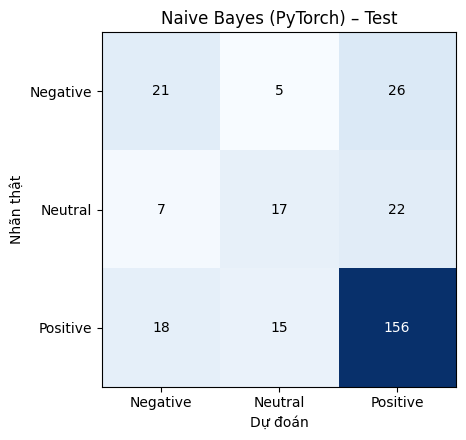

In [9]:
best_ng = eval(best["ngram"]); best_md = int(best["min_df"]); best_a = float(best["alpha"]); best_fp = bool(best["fit_prior"])
vec = TfidfTorch(best_ng, best_md, True).fit(X_tr_txt)
A_tr, A_va, A_te = (vec.transform(t) for t in (X_tr_txt, X_va_txt, X_te_txt))
nb = MultinomialNBTorch(best_a, best_fp).fit(A_tr, y_tr)
print("Cấu hình:", dict(ngram_range=best_ng, min_df=best_md, alpha=best_a, fit_prior=best_fp), "| |V| =", len(vec.vocab_))

def report(y, p, name):
    cm = confusion_matrix(y, p); prec, rec, f1 = prf_from_cm(cm)
    sup = cm.sum(1).double()
    r = pd.DataFrame({"precision": prec.cpu(), "recall": rec.cpu(), "f1-score": f1.cpu(), "support": sup.cpu()}, index=LABELS)
    r.loc["macro avg"] = [prec.mean().item(), rec.mean().item(), f1.mean().item(), sup.sum().item()]
    r.loc["accuracy"] = [np.nan, np.nan, accuracy(y, p), sup.sum().item()]
    print(f"== {name} =="); display(r.round(4)); return r, cm

p_va, p_te = nb.predict(A_va), nb.predict(A_te)
rep_va, _ = report(y_va, p_va, "VAL")
rep_te, cm_te = report(y_te, p_te, "TEST")
lo, hi = bootstrap_macro_f1_ci(y_te, p_te)
print(f"TEST macro-F1 = {macro_f1(y_te, p_te):.4f}  (bootstrap 95% CI: {lo:.4f} – {hi:.4f}, 2000 resamples, n_test={len(y_te)})")
base = torch.full_like(y_te, int(torch.bincount(y_tr).argmax()))
print(f"Baseline 'luôn đoán lớp đa số': acc = {accuracy(y_te, base):.4f}, macro-F1 = {macro_f1(y_te, base):.4f}")

rep_te.to_csv(OUT / "nb_test_metrics.csv")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm_te.cpu().numpy(), cmap="Blues")
ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn thật"); ax.set_title("Naive Bayes (PyTorch) – Test")
for i in range(3):
    for j in range(3):
        ax.text(j, i, int(cm_te[i, j]), ha="center", va="center", color="white" if cm_te[i, j] > cm_te.max() / 2 else "black")
plt.tight_layout(); plt.savefig(OUT / "nb_test_confusion_matrix.png", dpi=150); plt.show()

## 8. Phân tích bổ sung

### 8.1 Từ đặc trưng nhất của mỗi lớp
Xếp theo $\ln\theta_{ct}-\overline{\ln\theta_{c't}}_{c'\neq c}$ (mức *khác biệt* so với các lớp còn lại), vì xếp theo $\theta_{ct}$ thô chỉ cho ra stop-word ("phim", "không", "xem").

In [10]:
lt = nb.log_theta_
vocab = np.array(vec.vocab_)
top = {}
for c, name in enumerate(LABELS):
    others = lt[[k for k in range(3) if k != c]].mean(0)
    top[name] = vocab[(lt[c] - others).topk(12).indices.cpu().numpy()].tolist()
for k, v in top.items(): print(f"{k:9s}:", ", ".join(v))

Negative : thua, dở rất, dở_nha, nói_thẳng, phim rác, đường_máu hay, để tiền, nhái, phạm_thị_huệ_chi, phim thỏ, sickmyduck phim, sickmyduck
Neutral  : không người, beta, chiếu chưa, ah, không ta, không bạn, hẹ, không bà, không chị, có bạn, ai biết, có phụ_đề
Positive : hay chị, đáng xem, hay rất, hay bạn, phải đi, xứng_đáng, mới coi, liền, về hay, hay đáng, mê, xem lần


### 8.2 Learning curve — dữ liệu có "đủ giàu" chưa?
Train trên 25/50/75/100% tập train (5 lần lấy mẫu ngẫu nhiên mỗi mức; TF-IDF fit lại trên phần con), chấm macro-F1 trên **val**.

,frac,n_train,val_macro_f1_mean,val_macro_f1_std
0,0.25,372,0.5017,0.0313
1,0.50,745,0.5488,0.0178
2,0.75,1118,0.5758,0.0064
3,1.00,1491,0.6147,0.0000


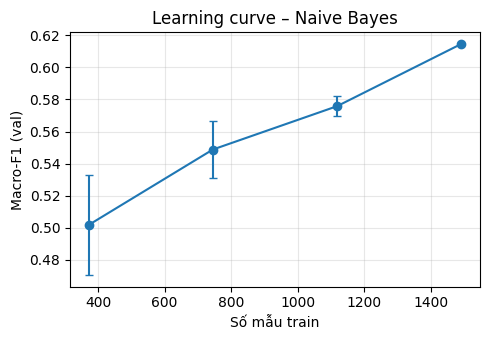

In [11]:
g = np.random.default_rng(0)
curve = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    s = []
    for _ in range(5):
        idx = g.choice(len(X_tr_txt), int(frac * len(X_tr_txt)), replace=False)
        sub = [X_tr_txt[i] for i in idx]
        v = TfidfTorch(best_ng, best_md, True).fit(sub)
        m = MultinomialNBTorch(best_a, best_fp).fit(v.transform(sub), y_tr[torch.tensor(idx, device=DEVICE)])
        s.append(macro_f1(y_va, m.predict(v.transform(X_va_txt))))
    curve.append(dict(frac=frac, n_train=int(frac * len(X_tr_txt)), val_macro_f1_mean=np.mean(s), val_macro_f1_std=np.std(s)))
curve = pd.DataFrame(curve); display(curve.round(4))
plt.figure(figsize=(5, 3.5)); plt.errorbar(curve.n_train, curve.val_macro_f1_mean, curve.val_macro_f1_std, marker="o", capsize=3)
plt.xlabel("Số mẫu train"); plt.ylabel("Macro-F1 (val)"); plt.title("Learning curve – Naive Bayes"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### 8.3 So sánh với mô hình tham chiếu (kết quả đã chạy trước đó bằng scikit-learn)
File `comparison_val_test.csv` được tạo ở lượt chạy trước (script sklearn) trên **đúng split này**; notebook chỉ đọc lại để đối chiếu, không huấn luyện lại các mô hình đó.

In [12]:
ref = OUT / "comparison_val_test.csv"
if ref.exists():
    display(pd.read_csv(ref)[["model", "val_macro_f1", "test_acc", "test_macro_f1", "test_macro_f1_ci95_lo", "test_macro_f1_ci95_hi"]].round(4))
else:
    print("Không tìm thấy", ref)

,model,val_macro_f1,test_acc,test_macro_f1,test_macro_f1_ci95_lo,test_macro_f1_ci95_hi
0,Naive Bayes (tuned),0.6147,0.6760,0.5440,0.4744,0.6124
1,Majority (baseline),0.2445,0.6585,0.2647,0.2516,0.2786
2,LogReg C=3,0.6051,0.7073,0.5884,0.5206,0.6491
3,LinearSVC C=1,0.6096,0.7073,0.5731,0.5004,0.6404


## 9. Lưu artifact và thông tin lần chạy

In [13]:
torch.save({"vocab": vec.vocab_, "idf": vec.idf_.cpu(), "log_prior": nb.log_prior_.cpu(), "log_theta": nb.log_theta_.cpu(),
            "classes": LABELS, "config": dict(ngram_range=best_ng, min_df=best_md, sublinear_tf=True, alpha=best_a, fit_prior=best_fp)},
           OUT / "naive_bayes_torch.pt")
info = {"seed": SEED, "torch": torch.__version__, "device": str(DEVICE), "split": split_info,
        "config": dict(ngram_range=list(best_ng), min_df=best_md, alpha=best_a, fit_prior=best_fp, n_features=len(vec.vocab_)),
        "val": {"macro_f1": macro_f1(y_va, p_va), "acc": accuracy(y_va, p_va)},
        "test": {"macro_f1": macro_f1(y_te, p_te), "acc": accuracy(y_te, p_te), "macro_f1_ci95": [lo, hi]},
        "top_features": top}
(OUT / "nb_run_info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")

# Hàm suy luận độc lập (chỉ cần file .pt)
def predict_texts(texts, path=OUT / "naive_bayes_torch.pt"):
    art = torch.load(path, weights_only=False)
    v = TfidfTorch(art["config"]["ngram_range"], art["config"]["min_df"], art["config"]["sublinear_tf"])
    v.vocab_, v.index_, v.idf_ = art["vocab"], {w: i for i, w in enumerate(art["vocab"])}, art["idf"].to(DEVICE)
    jll = v.transform(texts) @ art["log_theta"].to(DEVICE, DTYPE).T + art["log_prior"].to(DEVICE, DTYPE)
    return [art["classes"][i] for i in jll.argmax(1).tolist()]

print(predict_texts(["phim hay quá xem mà muốn khóc", "phim dở tệ phí tiền", "mấy giờ chiếu vậy bạn"]))
assert predict_texts(X_te_txt) == [LABELS[i] for i in p_te.tolist()], "suy luận từ .pt không khớp"
print("Suy luận từ file .pt khớp 100% với mô hình trong bộ nhớ trên test.")

['Positive', 'Negative', 'Neutral']
Suy luận từ file .pt khớp 100% với mô hình trong bộ nhớ trên test.



## 10. Kết luận và hạn chế

**Kết quả (VERIFIED, từ các ô ở trên):** Multinomial NB tự cài đặt bằng PyTorch (`ngram=(1,2)`, `min_df=2`, $\alpha=0.01$, `fit_prior=False`) đạt **macro-F1 = 0.544** trên test (bootstrap 95% CI ≈ 0.47–0.61), accuracy ≈ 0.68; baseline "luôn đoán Positive" chỉ có macro-F1 ≈ 0.26. Vectorizer và NB khớp `scikit-learn` đến sai số $\sim10^{-14}$–$10^{-16}$ (ô *Kiểm tra*), và kết quả trùng lượt chạy sklearn trước đó trên cùng split.

**Nhận xét (INFERRED):**
- NB phân biệt tốt Positive nhưng yếu ở Neutral/Negative (F1 ≈ 0.4). Các mô hình tuyến tính tham chiếu ở §8.3 cũng chỉ cao hơn một chút và khoảng tin cậy chồng lên nhau → nút thắt nhiều khả năng nằm ở **dữ liệu/nhãn** (lớp thiểu số nhỏ, nhãn Neutral/Negative nhiễu) hơn là thuật toán.
- Learning curve (§8.2) cho thấy macro-F1 còn tăng khi thêm dữ liệu nhưng đang chậm dần.
- Top features (§8.1) có lẫn tên riêng/spam/từ hiếm (ví dụ "sickmyduck", "hẹ", "beta") — dấu hiệu mô hình đang khớp các n-gram hiếm trong tập train nhỏ; $\alpha$ rất nhỏ (0.01) làm hiện tượng này mạnh hơn.

**Hạn chế:**
- Test chỉ có 287 mẫu → CI rộng; chênh lệch nhỏ giữa các mô hình không có ý nghĩa thống kê.
- $\alpha$ chọn trên val nhỏ (309 mẫu) nên có thể overfit val (val macro-F1 0.58–0.61 > test 0.54).
- Một seed, một split; chưa lặp nhiều seed hay cross-validation.
- Dùng TF-IDF (thực, không âm) thay cho đếm nguyên trong Multinomial NB: là thực hành phổ biến nhưng là xấp xỉ.
